In [1]:
import csv
import math
import statistics
from pathlib import Path

import matplotlib.pyplot as plt

In [2]:
# Resolve paths whether the kernel starts at the home, repository, or notebook directory.
working_dir = Path.cwd()
candidate_roots = [working_dir, working_dir / "ai4mi_project", working_dir.parent]
project_root = next(
    (root for root in candidate_roots
     if (root / "results/heldout_predictions/metrics").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Could not locate results/heldout_predictions/metrics from "
        f"the current directory ({working_dir})."
    )

metrics_before_path = project_root / "results/heldout_predictions/metrics"

# contains CSV metric files for each model after postprocessing
metrics_after_path = project_root / "results/heldout_predictions/metrics_postprocessed"

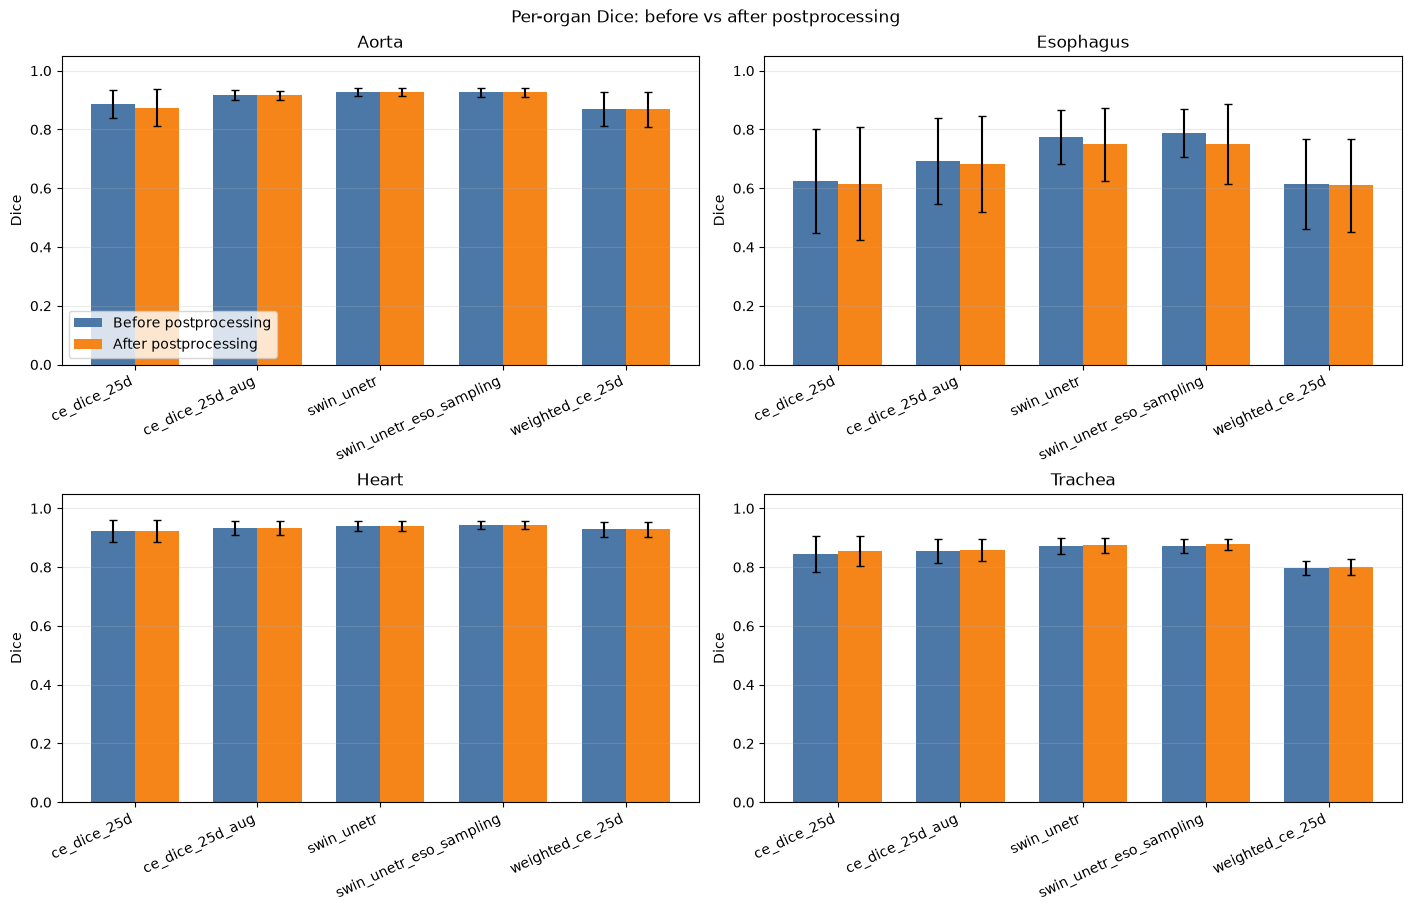

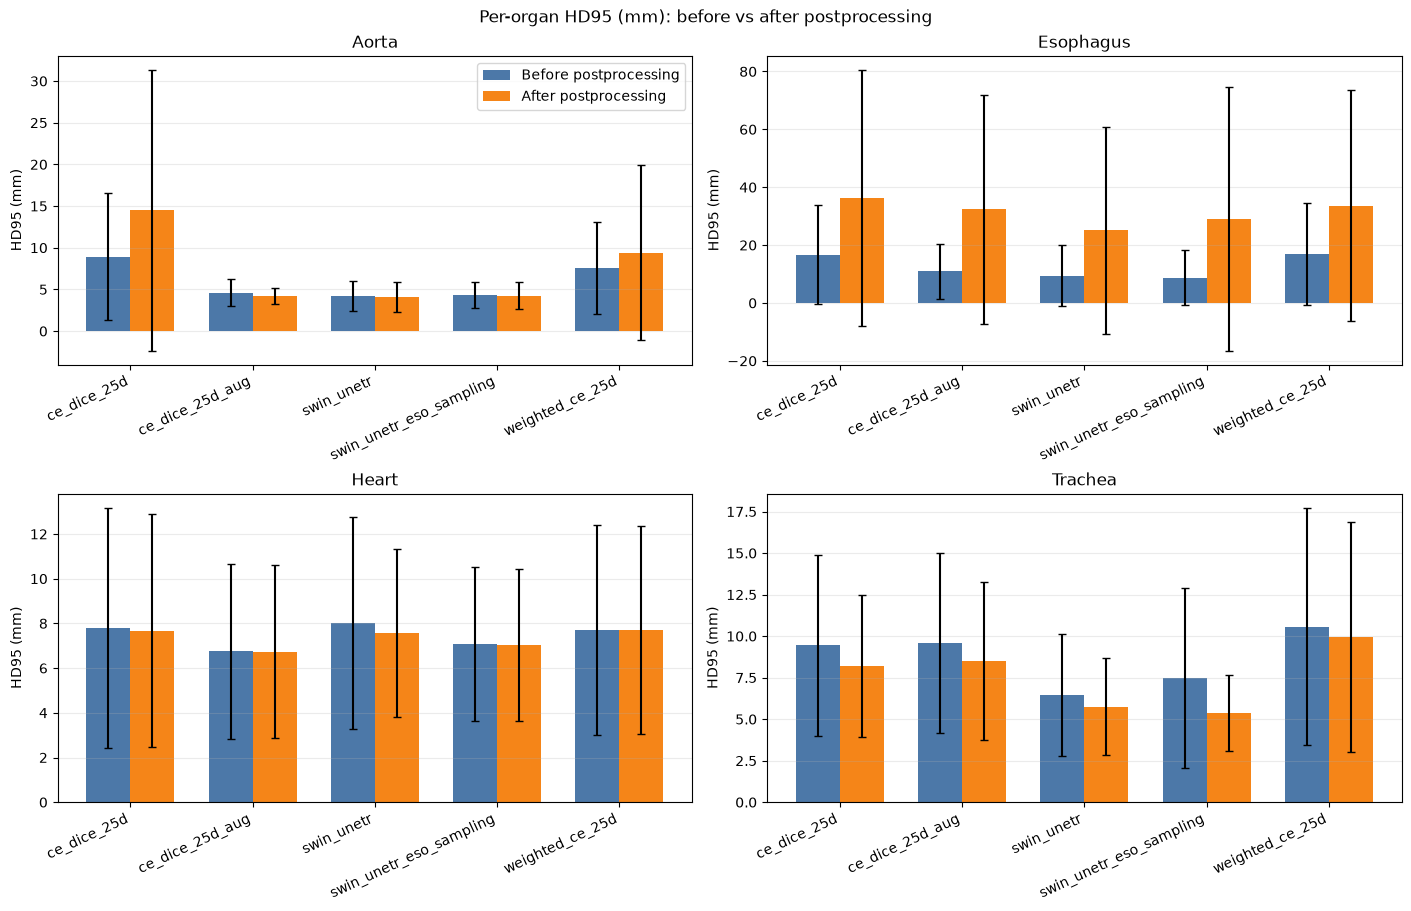

In [3]:
def read_metric_csv(path):
    # add prediction voxels
    required_columns = {"patient", "organ", "dice", "hd95_mm"}
    with path.open(newline="", encoding="utf-8") as metric_file:
        reader = csv.DictReader(metric_file)
        if not required_columns.issubset(reader.fieldnames or []):
            raise ValueError(
                f"{path} must contain these columns: {sorted(required_columns)}"
            )
        return list(reader)


before_files = {path.stem: path for path in metrics_before_path.glob("*.csv")}
after_files = {path.stem: path for path in metrics_after_path.glob("*.csv")}
paired_models = sorted(before_files.keys() & after_files.keys())

if not paired_models:
    raise FileNotFoundError(
        "No model has both a before and after CSV. Check the metric directories:\n"
        f"  before: {metrics_before_path}\n  after: {metrics_after_path}"
    )

missing_after = sorted(before_files.keys() - after_files.keys())
missing_before = sorted(after_files.keys() - before_files.keys())
if missing_after:
    print("Skipping models without postprocessed CSVs:", ", ".join(missing_after))
if missing_before:
    print("Skipping postprocessed CSVs without baseline CSVs:", ", ".join(missing_before))

metrics = {
    "before": {model: read_metric_csv(before_files[model]) for model in paired_models},
    "after": {model: read_metric_csv(after_files[model]) for model in paired_models},
}
metric_columns = {"Dice": "dice", "HD95 (mm)": "hd95_mm"}
organs = sorted({
    row["organ"]
    for condition in metrics.values()
    for rows in condition.values()
    for row in rows
    if row["organ"].lower() != "background"
})

def mean_and_std(rows, column, organ):
    values = [
        float(row[column])
        for row in rows
        if row["organ"] == organ
        and row[column].strip().lower() not in {"", "nan", "none"}
        and math.isfinite(float(row[column]))
    ]
    if not values:
        return math.nan, 0.0
    return statistics.mean(values), statistics.stdev(values) if len(values) > 1 else 0.0

x = list(range(len(paired_models)))
bar_width = 0.36
for metric_label, column in metric_columns.items():
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
    axes = axes.ravel()
    for ax, organ in zip(axes, organs):
        for offset, condition, label, color in [
            (-bar_width / 2, "before", "Before postprocessing", "#4C78A8"),
            (bar_width / 2, "after", "After postprocessing", "#F58518"),
        ]:
            stats = [
                mean_and_std(metrics[condition][model], column, organ)
                for model in paired_models
            ]
            means = [item[0] for item in stats]
            errors = [item[1] for item in stats]
            ax.bar(
                [position + offset for position in x], means, bar_width,
                yerr=errors, capsize=3, label=label, color=color,
            )
        ax.set_title(organ.capitalize())
        ax.set_xticks(x, paired_models, rotation=25, ha="right")
        ax.set_ylabel(metric_label)
        ax.grid(axis="y", alpha=0.25)
        if metric_label == "Dice":
            ax.set_ylim(0, 1.05)
    for ax in axes[len(organs):]:
        ax.set_visible(False)
    axes[0].legend()
    fig.suptitle(f"Per-organ {metric_label}: before vs after postprocessing")
    plt.show()

In [ ]:
# TODO not apply to all classes. 
# TODO denseCRF?